### Import Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score, f1_score

#Load Dataset

df = pd.read_csv('/content/2021 socio_economics.csv', sep = ';')
df.head()

,province,cities_reg,poorpeople_percentage,reg_gdp,life_exp,avg_schooltime,exp_percap
0,Aceh,Simeulue,18.98,2.275,65.240,9.48,7148
1,Aceh,Aceh Singkil,20.36,2.425,67.355,8.68,8776
2,Aceh,Aceh Selatan,13.18,5.531,64.360,8.88,8180
3,Aceh,Aceh Tenggara,13.41,5.063,68.155,9.67,8030
4,Aceh,Aceh Timur,14.45,10.616,68.705,8.21,8577


### Statistika Deskriptif

In [ ]:
#Informasi struktur data & Missing value
print("--- ringkasan dataset ---")
print(df.info())


--- ringkasan dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 514 entries, 0 to 513
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   province               514 non-null    object 
 1   cities_reg             514 non-null    object 
 2   poorpeople_percentage  514 non-null    float64
 3   reg_gdp                514 non-null    float64
 4   life_exp               514 non-null    float64
 5   avg_schooltime         514 non-null    float64
 6   exp_percap             514 non-null    int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 28.2+ KB
None


In [ ]:
#Statistika Deskriptif
print("\n--- Statistik Deskriptif Fitur Numerik ---")
print(df.describe())


--- Statistik Deskriptif Fitur Numerik ---
       poorpeople_percentage     reg_gdp    life_exp  avg_schooltime  \
count             514.000000  514.000000  514.000000      514.000000   
mean               12.273152   34.798333   69.619076        8.436615   
std                 7.458703   84.155498    3.455911        1.630842   
min                 2.380000    1.042000   55.370000        1.420000   
25%                 7.150000    5.587500   67.336250        7.510000   
50%                10.455000   13.068500   69.922500        8.305000   
75%                14.887500   28.849500   72.018750        9.337500   
max                41.660000  819.000000   77.855000       12.830000   

         exp_percap  
count    514.000000  
mean   10324.787938  
std     2717.144186  
min     3976.000000  
25%     8574.000000  
50%    10196.500000  
75%    11719.000000  
max    23888.000000  


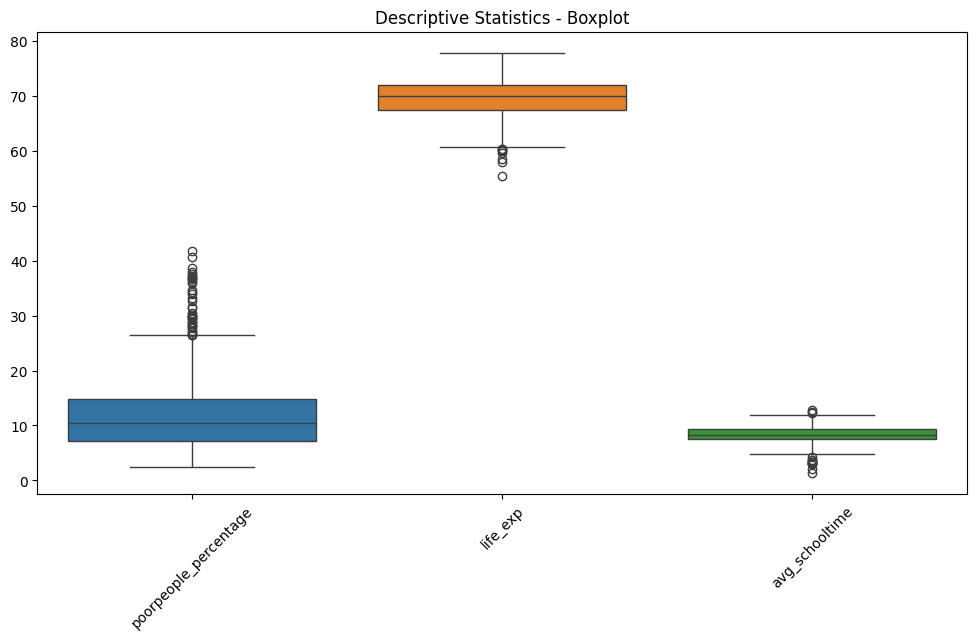

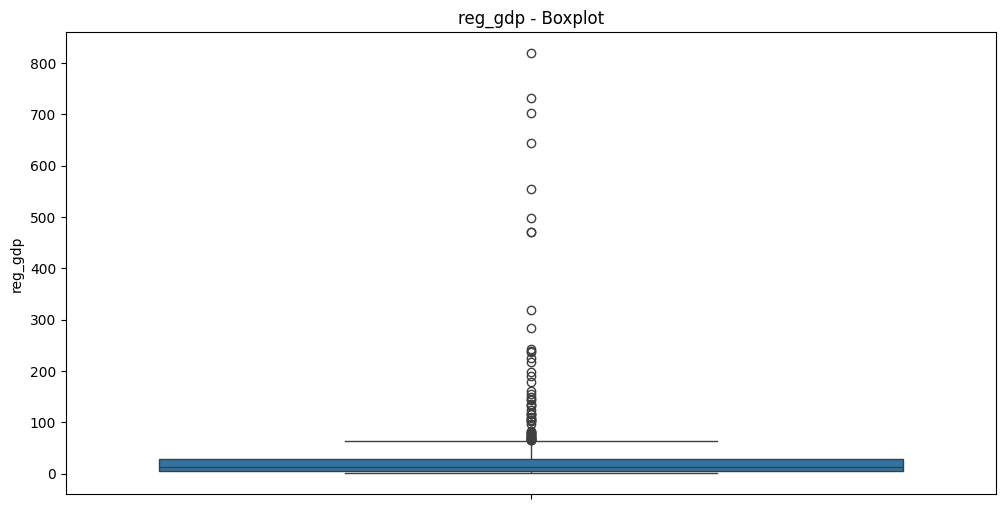

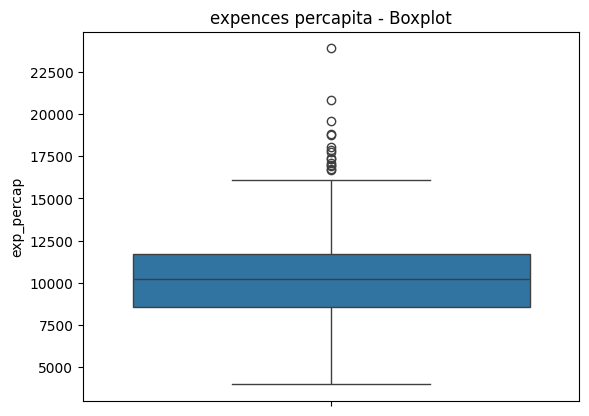

In [ ]:
#Boxplot Statistika Deskriptif
columns = [
    'poorpeople_percentage',
    'life_exp',
    'avg_schooltime'
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[columns])

plt.title('Descriptive Statistics - Boxplot')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))

sns.boxplot(data=df["reg_gdp"])

plt.title('reg_gdp - Boxplot')
plt.xticks(rotation=45)
plt.show()

sns.boxplot(data=df["exp_percap"])

plt.title('expences percapita - Boxplot')
plt.xticks(rotation=45)
plt.show()

#### Masing-masing variabel memiliki data outlier yang cukup banyak

### Data Wrangling : Klasifikasi Tingkat Kemiskinan

In [ ]:
# Rata-rata dari variabel poor people percentage digunakan sebagai batas untuk menentukan tingkat kemiskinan kota-kota di Indonesia.

df['target_kemiskinan'] = np.where(df['poorpeople_percentage'] > np.mean(
    df['poorpeople_percentage']), 1, 0)
df.head()



,province,cities_reg,poorpeople_percentage,reg_gdp,life_exp,avg_schooltime,exp_percap,target_kemiskinan
0,Aceh,Simeulue,18.98,2.275,65.240,9.48,7148,1
1,Aceh,Aceh Singkil,20.36,2.425,67.355,8.68,8776,1
2,Aceh,Aceh Selatan,13.18,5.531,64.360,8.88,8180,1
3,Aceh,Aceh Tenggara,13.41,5.063,68.155,9.67,8030,1
4,Aceh,Aceh Timur,14.45,10.616,68.705,8.21,8577,1


##### 1 = Tingkat kemiskinan tinggi, 0 = Tingkat kemiskinan rendah

##Visualisasi dan Asumsi Awal

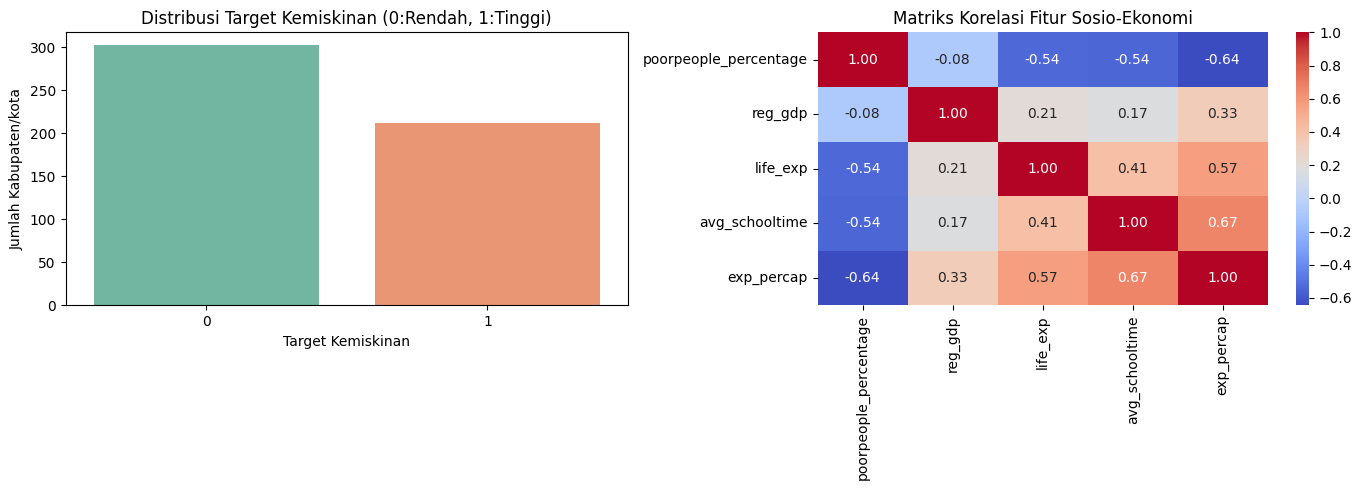

In [ ]:
#Visualisasi Distribusi Target & Korelasi Fitur
plt.figure(figsize=(14,5))

#Plot 1: Jumlah persebaran target klasifikasi
plt.subplot(1,2,1)
sns.countplot(data=df, x='target_kemiskinan', hue='target_kemiskinan', palette='Set2', legend=False)
plt.title('Distribusi Target Kemiskinan (0:Rendah, 1:Tinggi)')
plt.xlabel('Target Kemiskinan')
plt.ylabel('Jumlah Kabupaten/kota')

#plot 2: Heatmap Korelasi antar Fitur Numerik
plt.subplot(1,2,2)
numeric_cols = ['poorpeople_percentage', 'reg_gdp', 'life_exp', 'avg_schooltime', 'exp_percap']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Fitur Sosio-Ekonomi')

plt.tight_layout()
plt.show()

##### Daerah yang memiliki tingkat kemiskinan rendah lebih banyak dibandingkan yang tinggi jika dilihat dari bar chart di atas. Sedangkan untuk antar masing-masing variabel X sebagian besar tidak memiliki hubungan yang cukup signifikan dan kuat walaupun ada beberapa yang nilai korelasinya di atas 0,50

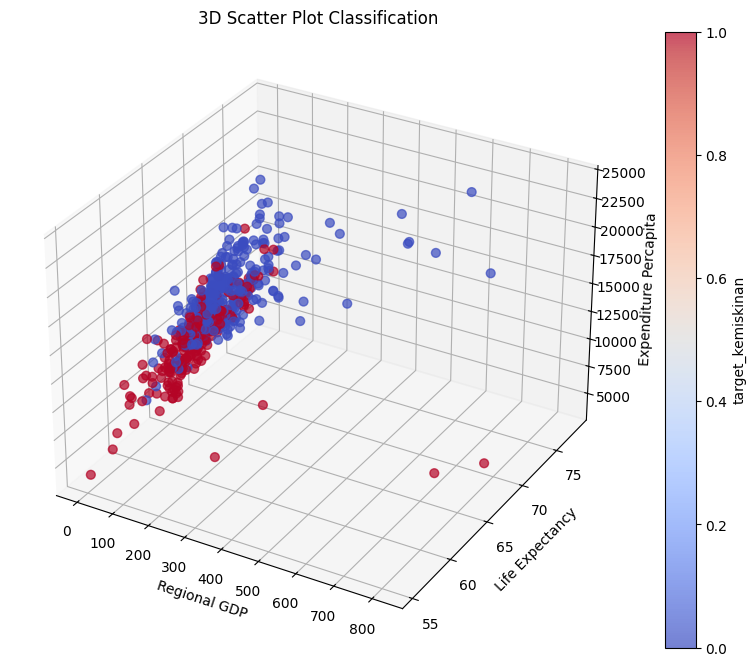

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    df['reg_gdp'],
    df['life_exp'],
    df['exp_percap'],
    c=df['target_kemiskinan'],
    cmap='coolwarm',
    alpha=0.7,
    s=40,
)

ax.set_xlabel('Regional GDP')
ax.set_ylabel('Life Expectancy')
ax.set_zlabel('Expenditure Percapita')

ax.set_title('3D Scatter Plot Classification')

plt.colorbar(scatter, label='target_kemiskinan')
plt.show()

#####Berdasarkan 3d scatter plot di atas, terjadi penumpukan antar data antar masing-masing kelasnya. Maka, dapat diinterpretasikan bahwa antar kedua kelas masih memiliki karakteristik yang sama untuk masing-masing fitur yang menjadi acuan pembeda kelas. Selain itu, penyebaran data terlihat terkonsentrasi di daerah gdp rendah pada variabel regional gdp. Oleh karena itu, model klasifikasi yang akan dibuat diharapkan memiliki kualitas yang cukup baik dalam mengklasifikasikan data walaupun karakteristiknya datanya serupa.

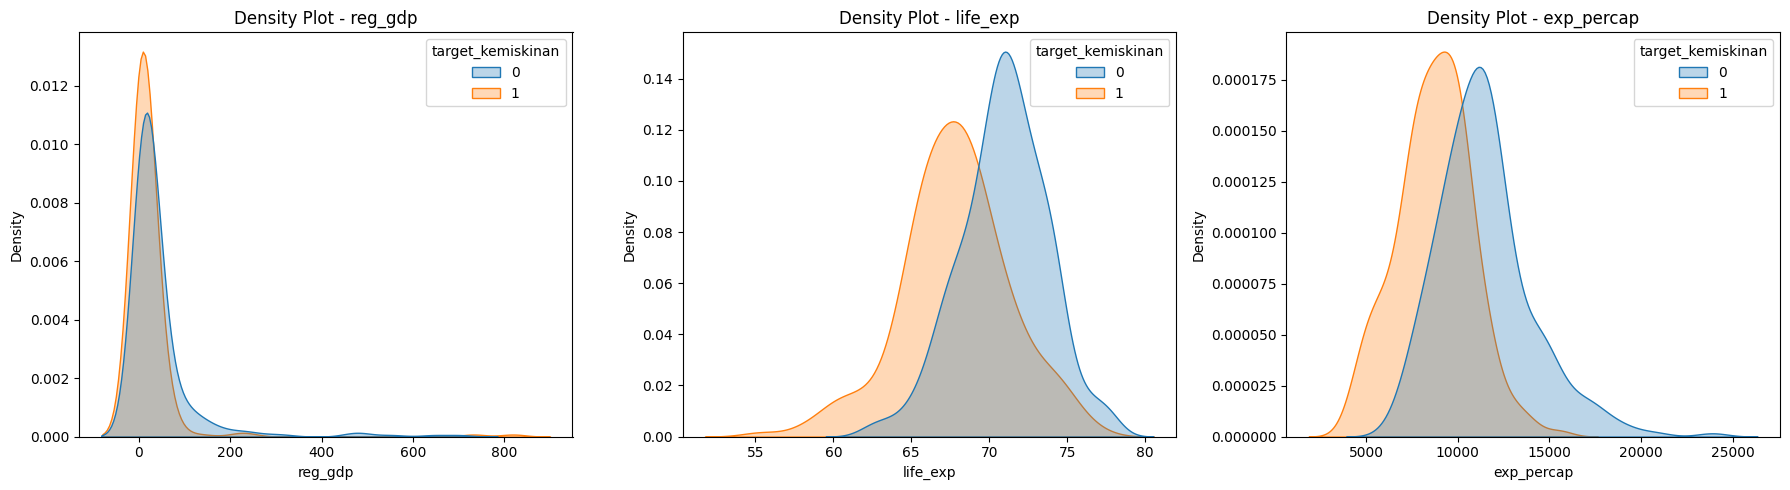

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

features = ['reg_gdp', 'life_exp', 'exp_percap']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features):
    sns.kdeplot(
        data=df,
        x=feature,
        hue='target_kemiskinan',
        fill=True,
        alpha=0.3,
        common_norm=False,
        ax=axes[i]
    )

    axes[i].set_title(f'Density Plot - {feature}')

plt.tight_layout()
plt.show()

##### Regional GDP : Kedua kelas memiliki rata-rata yang sangat berdekatan dan distribusi data kelas 1 lebih menyempit di sekitar rata-rata. Dapat dilihat juga penyebaran datanya terlihat cenderung serupa antar kedua kelas.

##### Life Expectancy : Kelas 0 memiliki rata-rata yang lebih tinggi dan distribusinya lebih menyempit terhadap rata-rata dibandingkan kelas 1.

##### Expenditure Percapita : Rata-rata kelas 0 lebih tinggi dibanding kelas 1 akan tetapi distribusinya lebih menyebar.


##Modelling

###Gaussian Naive Bayes

In [ ]:
features = ['reg_gdp', 'life_exp', 'exp_percap']
X = df[features]
y = df['target_kemiskinan']

X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Model Gaussian Naive Bayes
model_nb = GaussianNB()
model_nb.fit(X_train_scaled, y_train)
y_pred_nb = model_nb.predict(X_test_scaled)

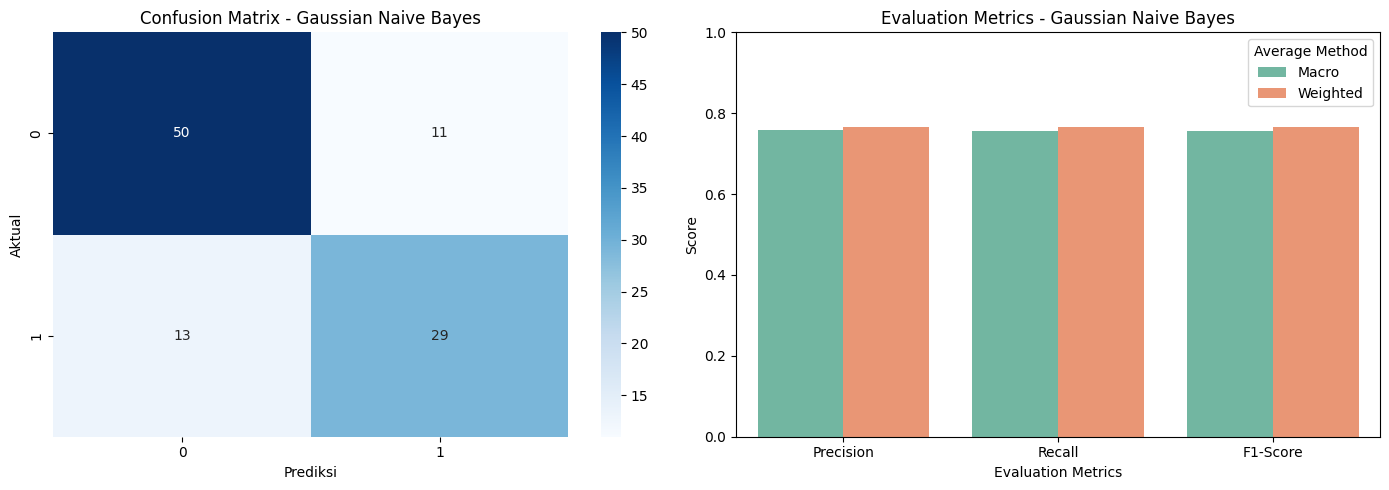

In [ ]:
# Menampilkan Confusion Matrix & Grafik Evaluasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Naive Bayes
sns.heatmap(
    confusion_matrix(y_test, y_pred_nb),
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Confusion Matrix - Gaussian Naive Bayes')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# 2. Menghitung Evaluation Metrics

# Macro Average
macro = {
    'Precision': precision_score(y_test, y_pred_nb, average='macro'),
    'Recall': recall_score(y_test, y_pred_nb, average='macro'),
    'F1-Score': f1_score(y_test, y_pred_nb, average='macro')
}

# Weighted Average
weighted = {
    'Precision': precision_score(y_test, y_pred_nb, average='weighted'),
    'Recall': recall_score(y_test, y_pred_nb, average='weighted'),
    'F1-Score': f1_score(y_test, y_pred_nb, average='weighted')
}

# 3. Membuat DataFrame
evaluation_df = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'F1-Score'] * 2,
    'Score': list(macro.values()) + list(weighted.values()),
    'Average': ['Macro'] * 3 + ['Weighted'] * 3
})

# 4. Visualisasi Evaluation Metrics
sns.barplot(
    data=evaluation_df,
    x='Metric',
    y='Score',
    hue='Average',
    palette='Set2',
    ax=axes[1]
)

axes[1].set_title('Evaluation Metrics - Gaussian Naive Bayes')
axes[1].set_xlabel('Evaluation Metrics')
axes[1].set_ylabel('Score')
axes[1].set_ylim(0, 1)
axes[1].legend(title='Average Method')

# 5. Menampilkan kedua grafik
plt.tight_layout()
plt.show()


##### Berdasarkan confussion matrix di atas,
##### 50 : Model berhasil mengklasifikasikan kategori Rendah dengan benar. (TN)
##### 11 data: Model salah mengklasifikasikan kategori Rendah menjadi Tinggi. (FP)
##### 13 data: Model salah mengklasifikasikan kategori Tinggi menjadi Rendah. (FN)
##### 29 data: Model berhasil mengklasifikasikan kategori Tinggi dengan benar. (TP)
##### Tingkat akurasi model adalah sebesar 76,7% dengan 79 prediksi benar dan 24 prediksi salah.
##### Model lebih sering salah mengklasifikasikan kategori Tinggi menjadi Rendah (13 data) dibandingkan sebaliknya (11 data).



##### Selanjutnya, perbandingan Macro Average dan Weighted Average menghasilkan nilai Precision masing-masing sebesar 0,76 dan 0,77, Recall sebesar 0,76 dan 0,77, serta F1-Score sebesar 0,76 dan 0,77. Perbedaan tersebut menunjukkan bahwa pembobotan berdasarkan jumlah observasi setiap kelas memengaruhi hasil evaluasi model walaupun perbedaan angkanya sangat kecil.

In [ ]:
#Laporan Evaluasi Lengkap
print("================ LAPORAN VALIDASI NAIVE BAYES ================")
print(f"Akurasi: {accuracy_score(y_test, y_pred_nb)*100:.2f}%")
print(classification_report(y_test, y_pred_nb, target_names=['Rendah (0)', 'Tinggi (1)']))

================ LAPORAN VALIDASI NAIVE BAYES ================
Akurasi: 76.70%
              precision    recall  f1-score   support

  Rendah (0)       0.79      0.82      0.81        61
  Tinggi (1)       0.72      0.69      0.71        42

    accuracy                           0.77       103
   macro avg       0.76      0.76      0.76       103
weighted avg       0.77      0.77      0.77       103



##### Hasil evaluasi menunjukkan bahwa model memiliki kemampuan yang lebih baik dalam mengidentifikasi kategori Rendah dibandingkan kategori Tinggi. Hal ini ditunjukkan oleh nilai Recall dan f1-score kategori Rendah sebesar 0,82 dan 0.81, sedangkan kategori Tinggi hanya sebesar 0,69 dan 0,71.

In [ ]:
from sklearn.metrics import roc_auc_score

# Menghitung probabilitas prediksi
y_prob_nb = model_nb.predict_proba(X_test)[:, 1]

# Menghitung ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob_nb)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.5


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but GaussianNB was fitted without feature names
  warnings.warn(


##### ROC Score (Receiver Operating Characteristic) adalah metrik evaluasi dalam Machine Learning yang digunakan untuk mengukur kemampuan model klasifikasi dalam membedakan dua kelas. Nilai ROC_AUC untuk model ini adalah sebesar 0,5 yang artinya model masih belum baik dalam membedakan kelas 0 dan kelas 1 berdasarkan skor probabilitasnya (setara dengan random guessing)

## Logistic Regression

In [ ]:
#Model Logistic Regression
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)

--- Pengaruh Fitur terhadap kemiskinan (Koefisien Logistic Regression) ---
        Fitur  Koefisien
2  exp_percap  -1.279576
1    life_exp  -0.605099
0     reg_gdp  -0.029952


/tmp/ipykernel_1248/337994014.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Koefisien', y='Fitur', data=importances, palette='viridis')


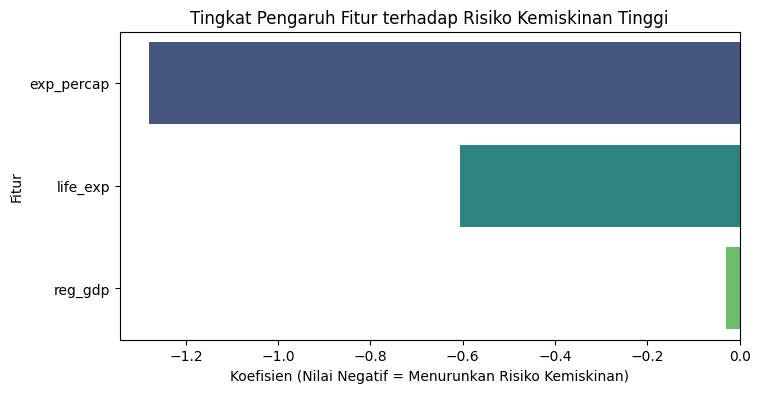

In [ ]:
#Melihat pengaruh tiap fitur pada Logistic Regression
importances = pd.DataFrame({'Fitur': features, 'Koefisien': model_lr.coef_[0]
                            }).sort_values(by='Koefisien')
print("--- Pengaruh Fitur terhadap kemiskinan (Koefisien Logistic Regression) ---")
print(importances)

plt.figure(figsize=(8, 4))
sns.barplot(x='Koefisien', y='Fitur', data=importances, palette='viridis')
plt.title('Tingkat Pengaruh Fitur terhadap Risiko Kemiskinan Tinggi')
plt.xlabel('Koefisien (Nilai Negatif = Menurunkan Risiko Kemiskinan)')
plt.show()

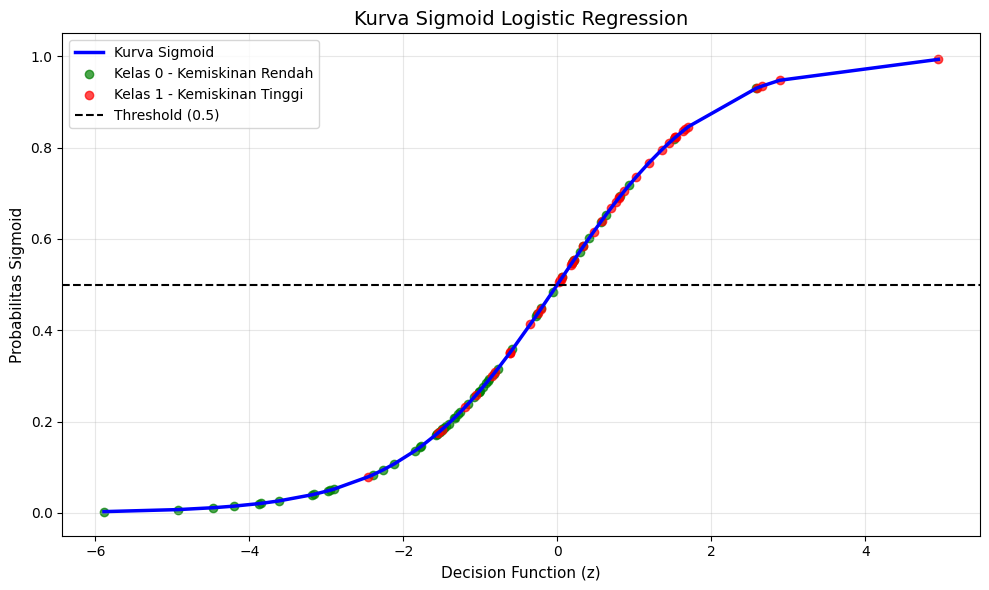

In [ ]:

# ==========================================
# VISUALISASI KURVA SIGMOID LOGISTIC REGRESSION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# 1. Mengambil nilai decision function dari model
z = model_lr.decision_function(X_test_scaled)

# 2. Menghitung probabilitas menggunakan fungsi sigmoid
sigmoid = 1 / (1 + np.exp(-z))

# 3. Mengambil label aktual
y_actual = np.array(y_test)

# 4. Mengurutkan nilai z agar kurva sigmoid terlihat halus
sorted_indices = np.argsort(z)
z_sorted = z[sorted_indices]
sigmoid_sorted = sigmoid[sorted_indices]

# 5. Membuat grafik
plt.figure(figsize=(10, 6))

# Kurva sigmoid
plt.plot(
    z_sorted,
    sigmoid_sorted,
    color='blue',
    linewidth=2.5,
    label='Kurva Sigmoid'
)

# Titik data kelas 0 (Kemiskinan Rendah)
plt.scatter(
    z[y_actual == 0],
    sigmoid[y_actual == 0],
    color='green',
    alpha=0.7,
    label='Kelas 0 - Kemiskinan Rendah'
)

# Titik data kelas 1 (Kemiskinan Tinggi)
plt.scatter(
    z[y_actual == 1],
    sigmoid[y_actual == 1],
    color='red',
    alpha=0.7,
    label='Kelas 1 - Kemiskinan Tinggi'
)

# Garis threshold 0.5
plt.axhline(
    y=0.5,
    color='black',
    linestyle='--',
    label='Threshold (0.5)'
)

# Pengaturan grafik
plt.title('Kurva Sigmoid Logistic Regression', fontsize=14)
plt.xlabel('Decision Function (z)', fontsize=11)
plt.ylabel('Probabilitas Sigmoid', fontsize=11)
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


#####Berdasarkan distribusi nilai sigmoid di atas, terjadi beberapa kesalahan klasifikasi yang dilakukan oleh model. Data dengan tingkat kemiskinan tinggi terklasifikasi rendah oleh model dan begitu juga sebaliknya. Hal ini menunjukkan bahwa model masih memiliki kekurangan dalam mengklasifikasikan data.  

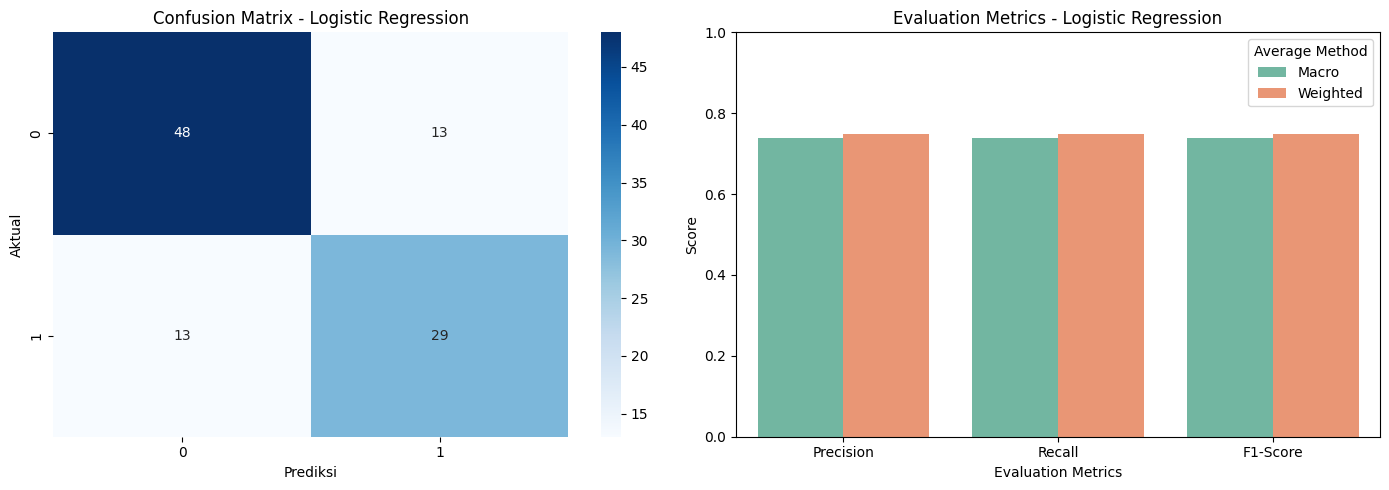

In [ ]:
# Menampilkan Confusion Matrix & Grafik Evaluasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Naive Bayes
sns.heatmap(
    confusion_matrix(y_test, y_pred_lr),
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Confusion Matrix - Logistic Regression')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# 2. Menghitung Evaluation Metrics

# Macro Average
macro = {
    'Precision': precision_score(y_test, y_pred_lr, average='macro'),
    'Recall': recall_score(y_test, y_pred_lr, average='macro'),
    'F1-Score': f1_score(y_test, y_pred_lr, average='macro')
}

# Weighted Average
weighted = {
    'Precision': precision_score(y_test, y_pred_lr, average='weighted'),
    'Recall': recall_score(y_test, y_pred_lr, average='weighted'),
    'F1-Score': f1_score(y_test, y_pred_lr, average='weighted')
}

# 3. Membuat DataFrame
evaluation_df = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'F1-Score'] * 2,
    'Score': list(macro.values()) + list(weighted.values()),
    'Average': ['Macro'] * 3 + ['Weighted'] * 3
})

# 4. Visualisasi Evaluation Metrics
sns.barplot(
    data=evaluation_df,
    x='Metric',
    y='Score',
    hue='Average',
    palette='Set2',
    ax=axes[1]
)

axes[1].set_title('Evaluation Metrics - Logistic Regression')
axes[1].set_xlabel('Evaluation Metrics')
axes[1].set_ylabel('Score')
axes[1].set_ylim(0, 1)
axes[1].legend(title='Average Method')

# 5. Menampilkan kedua grafik
plt.tight_layout()
plt.show()

In [ ]:
print("============ LAPORAN VALIDASI LOGISTIC REGRESSION ============")
print(f"Akurasi: {accuracy_score(y_test, y_pred_lr)*100:.2f}%")
print(classification_report(y_test, y_pred_lr, target_names=['Rendah (0)', 'Tinggi (1)']))

============ LAPORAN VALIDASI LOGISTIC REGRESSION ============
Akurasi: 74.76%
              precision    recall  f1-score   support

  Rendah (0)       0.79      0.79      0.79        61
  Tinggi (1)       0.69      0.69      0.69        42

    accuracy                           0.75       103
   macro avg       0.74      0.74      0.74       103
weighted avg       0.75      0.75      0.75       103



In [ ]:
from sklearn.metrics import roc_auc_score

# Menghitung probabilitas prediksi
y_prob_lr = model_lr.predict_proba(X_test)[:, 1]

# Menghitung ROC-AUC
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("ROC-AUC Score:", roc_auc_lr)

ROC-AUC Score: 0.5


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


##### ROC Score (Receiver Operating Characteristic) adalah metrik evaluasi dalam Machine Learning yang digunakan untuk mengukur kemampuan model klasifikasi dalam membedakan dua kelas. Nilai ROC_AUC untuk model ini adalah sebesar 0,5 yang artinya model masih belum baik dalam membedakan kelas 0 dan kelas 1 berdasarkan skor probabilitasnya (setara dengan random guessing)